# 視覚言語モデルで画像を説明し、画像について質問に答える (VQA)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/30_vision_language/vlm_vqa.ipynb)

NLP クックブック 30-02 ／ 画像と言語

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

画像を入力して、日本語で説明文を作らせたり、画像についての質問（何が写っているか、いくつあるか、何色か、どこにあるか、何と書いてあるか）に答えさせたりしたい。視覚言語モデル (VLM) の Qwen3-VL-4B-Instruct を transformers で動かし、得意なことと苦手なことを確かめ、日本語の VQA データで正解との一致を測る。

In [1]:
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

# 初回はモデル (約 8.3GB) のダウンロードに数分かかる
name = "Qwen/Qwen3-VL-4B-Instruct"   # Apache 2.0。画像エンコーダ (ViT) + 射影 + 4B の LLM
processor = AutoProcessor.from_pretrained(name)   # 画像の前処理 (リサイズ・パッチ分割) とトークナイザをまとめたもの
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
model = AutoModelForImageTextToText.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="cuda").eval()

count = lambda m: sum(p.numel() for p in m.parameters()) / 1e9
print(type(model).__name__, f"画像エンコーダ {count(model.model.visual):.2f}B / LLM {count(model.model.language_model):.2f}B")
print(f"{model.dtype}, GPU メモリ: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
print(model.model.visual.merger)   # 画像の特徴を LLM の埋め込み (2560 次元) に写す射影

Qwen3VLForConditionalGeneration 画像エンコーダ 0.42B / LLM 4.02B
torch.float16, GPU メモリ: 8.9 GB
Qwen3VLVisionPatchMerger(
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
  (linear_fc1): Linear(in_features=4096, out_features=4096, bias=True)
  (act_fn): GELU(approximate='none')
  (linear_fc2): Linear(in_features=4096, out_features=2560, bias=True)
)


(500, 375) (3072, 4080)


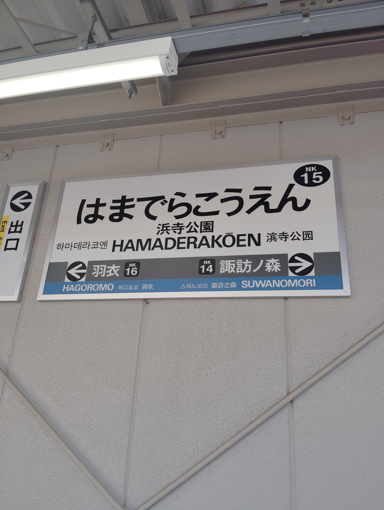

In [2]:
import io
import requests
from datasets import load_dataset
from PIL import Image, ImageOps

# 日本語の VQA データ JA-VG-VQA-500 (SakanaAI、CC BY 4.0)。Visual Genome (Krishna et al., 2017) の画像に
# 日本語の質問と答えを付けた JA-VG-VQA (Shimizu et al., 2018) から 500 枚。画像は Visual Genome 経由の Flickr の写真で、
# 写真ごとのライセンスはデータセットのライセンスとは別 (vqa[i]["flickr_id"] で元の写真をたどれる)
# parquet を直接読むと分割名は "train" になるが、中身はテスト分割の 500 件
vqa = load_dataset("parquet", data_files="hf://datasets/SakanaAI/JA-VG-VQA-500/data/test-00000-of-00001.parquet", split="train")
food = vqa[31]["image"].convert("RGB")

# 浜寺公園駅 (大阪府堺市、南海本線) の駅名標。Wikimedia Commons、作者 Tatsuya tetsudo、CC0 (パブリックドメイン)
url = "https://upload.wikimedia.org/wikipedia/commons/e/ed/%E6%B5%9C%E5%AF%BA%E5%85%AC%E5%9C%92%E9%A7%85_%E9%A7%85%E5%90%8D%E6%A8%99.jpg"
res = requests.get(url, headers={"User-Agent": "nlpcookbook-example/0.1"}, timeout=60)   # Wikimedia は User-Agent がないと断られる
sign = ImageOps.exif_transpose(Image.open(io.BytesIO(res.content))).convert("RGB")
print(food.size, sign.size)
display(food, sign.resize((sign.width // 8, sign.height // 8)))

In [3]:
import time

def ask(image, text, max_new_tokens=128, max_image_tokens=1024):
    """画像 1 枚と質問文を 1 つのメッセージに入れて生成する。max_image_tokens で画像のトークン数の上限を決める"""
    messages = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": text}]}]
    # 1 トークン = 32×32 画素 (16×16 のパッチを 2×2 まとめる)。画素数をこの範囲に収まるようにリサイズする
    size = {"shortest_edge": 32 * 32 * 16, "longest_edge": 32 * 32 * max_image_tokens}
    inputs = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                           return_tensors="pt", processor_kwargs={"size": size}).to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# テンプレートの中身: 画像は <|image_pad|> の位置に、画像のトークン数だけ展開される
messages = [{"role": "user", "content": [{"type": "image", "image": food}, {"type": "text", "text": "説明してください。"}]}]
print(processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=False))
inputs = processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt")
print("グリッド (時間, 縦, 横) =", inputs["image_grid_thw"].tolist(), "→ 画像のトークン数",
      (inputs["input_ids"] == model.config.image_token_id).sum().item(), "/ 全体", inputs["input_ids"].shape[1])

for prompt in ["この画像を日本語で一文で説明してください。", "この画像を日本語で詳しく説明してください。"]:
    t = time.perf_counter()
    caption = ask(food, prompt, max_new_tokens=400)
    print(f"\n## {prompt} ({len(caption)} 文字, {time.perf_counter() - t:.1f} 秒)\n{caption}")

<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>説明してください。<|im_end|>
<|im_start|>assistant

グリッド (時間, 縦, 横) = [[1, 24, 32]] → 画像のトークン数 192 / 全体 207

## この画像を日本語で一文で説明してください。 (40 文字, 3.8 秒)
カレー、豆、人参、ブロッコリーが入った容器とバナナが大理石の台の上に並んでいる。

## この画像を日本語で詳しく説明してください。 (595 文字, 13.3 秒)
この画像は、大理石模様のカウンターの上に並べられた4つの容器と、その隣に置かれたバナナを写したものです。全体的に健康的な食事やスナックの準備がされている様子が伺えます。

---

### 1. 左上：白い豆（おそらくピーナッツまたはホワイトビーン）
- **容器**：白いプラスチック製の丸いボウル。
- **内容物**：白い豆が満たされており、表面は滑らかで、粒が均一に見える。これは「ホワイトビーン」や「ピーナッツ」の可能性がありますが、ピーナッツは通常茶色っぽいので、ここでは「ホワイトビーン」または「白い豆類」であると推測されます。
- **特徴**：豆はふっくらと柔らかく、栄養価の高い主食として使われている可能性があります。

---

### 2. 右上：カレー風の料理（おそらくポテトカレー）
- **容器**：白いプラスチック製の丸いボウル。
- **内容物**：茶色のカレー風の料理で、中にはポテトの角切りが見えます。カレーのソースは濃厚で、香辛料が入っているように見えます。
- **特徴**：ポテトが主役で、カレーの風味が加えられており、温かい料理として提供されている可能性があります。

---

### 3. 左下：人参（小ぶりの人参）
- **容器**：白いプラスチック製の丸いボウル。
- **内容物**：小ぶりな人参が数本、整然と並べられています。色は鮮


In [4]:
# 物の種類・数・色・位置について質問する。データに付いている人手の答えと並べる (最後の 2 問は自分で足した質問)
qas = [(qa["question"], qa["answer"]) for qa in vqa[31]["qas"]] + [("人参は何本ありますか？", "6本 (目視で数えた)"), ("スプーンは何色ですか？", "(スプーンは写っていない)")]
for q, gold in qas:
    print(f"Q: {q}\n  正解: {gold}\n  VLM : {ask(food, q + ' 短く答えてください。', max_new_tokens=60)}")

Q: 器は全部でいくつありますか？
  正解: ４つ
  VLM : 4
Q: 丸い形の器は全部でいくつありますか？
  正解: ４つ
  VLM : 4
Q: 器に入ってない果物は何ですか？
  正解: バナナ
  VLM : バナナ
Q: バナナは全部でいくつありますか？
  正解: １本
  VLM : 1
Q: 右手前の器に入っているのはどんな野菜ですか？
  正解: ブロッコリー
  VLM : 人参
Q: 左手前の器に入っているのはどんな野菜ですか？
  正解: 人参
  VLM : 人参
Q: 右手前の器に入っている野菜はどんな色ですか？
  正解: 緑色
  VLM : オレンジ色
Q: 左手前の器に入っている野菜はどんな色ですか？
  正解: オレンジ色
  VLM : オレンジ色
Q: 人参は何本ありますか？
  正解: 6本 (目視で数えた)
  VLM : 0
Q: スプーンは何色ですか？
  正解: (スプーンは写っていない)
  VLM : なし


In [5]:
# 画像の中の文字を読む・位置関係を答える・画像の外の知識を問う
for q in ["駅名標に書かれている文字をすべて書き出してください。",
          "この駅の名前は何ですか？",
          "左向きの矢印の先にある隣の駅は？", "右向きの矢印の先にある隣の駅は？",
          "この駅は何県にありますか？短く答えてください。",
          "この駅は何県にありますか？画像から判断できなければ「わからない」と答えてください。"]:
    print(f"Q: {q}\nA: {ask(sign, q, max_new_tokens=150)}\n")

Q: 駅名標に書かれている文字をすべて書き出してください。
A: はまでらこうえん
浜寺公園
하마데라코엔 HAMADERAKŌEN 浜寺公園
羽衣 NK 16
観訪ノ森 NK 14
HAGOROMO 하고로모 羽衣
스위노모리 観訪之森 SUWANOMORI
NK 15
出口
EXIT

Q: この駅の名前は何ですか？
A: この駅の名前は **浜寺公園駅**（はまだらこうえんえき）です。

駅名標には「はまでらこうえん」（浜寺公園）と明記されており、その下に「HAMADERAKŌEN」（ハマデラコエン）というローマ字表記も見えます。また、駅の番号は「NK 15」で、これは大阪市営地下鉄の駅番号です。

この駅は大阪市東淀川区に位置し、大阪市営地下鉄の「千日前線」に属しています。

Q: 左向きの矢印の先にある隣の駅は？
A: 左向きの矢印の先にある隣の駅は **羽衣駅（HAGOROMO）** です。

駅名標の左側（左向き矢印の方向）には「羽衣」の文字と駅名「HAGOROMO」が記されており、これは左に進む方向の次の駅を示しています。

Q: 右向きの矢印の先にある隣の駅は？
A: 右向きの矢印の先にある隣の駅は **諏訪ノ森**（SUWANOMORI）です。

駅の案内板に記載されている通り、右向きの矢印は「諏訪ノ森」方面を指しており、その駅名は案内板の右側に明記されています。また、駅名の下には「SUWANOMORI」と英語表記も併記されています。

---

**補足：**

- 左向きの矢印の先は **羽衣**（HAGOROMO）方面。
- 本駅は **浜寺公園**（HAMADERAKOEN）

Q: この駅は何県にありますか？短く答えてください。
A: 千葉県

Q: この駅は何県にありますか？画像から判断できなければ「わからない」と答えてください。
A: この駅は**千葉県**にあります。

駅名「浜寺公園（はまだらこうえん）」は、千葉県千葉市美浜区にある**浜寺公園駅**です。駅の標識には「HAMADERAKŌEN」（浜寺公園）と記載されており、千葉県の駅として知られています。また、隣接する駅（羽衣駅、諏訪ノ森駅）も千葉県の駅であり、この駅の位置も千葉県内であることが確認できます。

したがって、答えは：

**千葉県**



正解  3 → VLM 3
正解  5 → VLM 4
正解  8 → VLM 8
正解 12 → VLM 10
正解 17 → VLM 15
正解 25 → VLM 20


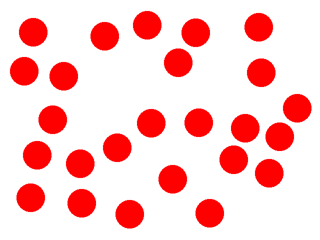

In [6]:
# 数を数える: 正解がわかるように、赤い丸を n 個描いた画像を作って数えさせる
import random
from PIL import ImageDraw

def circles(n, seed=0, size=(640, 480), r=28):
    rng = random.Random(seed)
    img = Image.new("RGB", size, "white"); draw = ImageDraw.Draw(img); centers = []
    while len(centers) < n:
        x, y = rng.randrange(r + 5, size[0] - r - 5), rng.randrange(r + 5, size[1] - r - 5)
        if all((x - a) ** 2 + (y - b) ** 2 > (2 * r + 10) ** 2 for a, b in centers):   # 重ならないように置く
            centers.append((x, y)); draw.ellipse([x - r, y - r, x + r, y + r], fill="red")
    return img

for n in [3, 5, 8, 12, 17, 25]:
    print(f"正解 {n:2d} → VLM {ask(circles(n, seed=n), '赤い丸はいくつありますか？数字だけで答えてください。', max_new_tokens=10)}")
display(circles(25, seed=25).resize((320, 240)))

In [7]:
# 画像のトークン数 (解像度) と、速度・GPU メモリ・文字の読み取りの関係
# 駅名標の元画像は 3072×4080 画素。既定の上限 (16384 トークン) では約 1.2 万トークンになる
for max_tokens in [64, 256, 1024, 4096, 16384]:
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    size = {"shortest_edge": 32 * 32 * 16, "longest_edge": 32 * 32 * max_tokens}
    n = processor.image_processor(images=[sign], size=size)["image_grid_thw"].prod().item() // 4   # 2×2 のパッチで 1 トークン
    torch.cuda.synchronize(); t = time.perf_counter()
    answer = ask(sign, "駅名標に書かれている漢字の駅名を、左の駅・この駅・右の駅の順に書いてください。", max_new_tokens=40, max_image_tokens=max_tokens)
    torch.cuda.synchronize()
    print(f"上限 {max_tokens:5d} → 画像 {n:5d} トークン, {time.perf_counter() - t:5.1f} 秒, "
          f"最大メモリ {torch.cuda.max_memory_allocated() / 1e9:.1f} GB: {answer!r}")

上限    64 → 画像    54 トークン,   2.1 秒, 最大メモリ 8.9 GB: '左の駅：**東寺公園**  \nこの駅：**はまでらこうえん**（はまでらこうえん）  \n右の駅：**南�'
上限   256 → 画像   234 トークン,   0.9 秒, 最大メモリ 9.0 GB: '羽衣\u3000浜寺公園\u3000諏訪ノ森'
上限  1024 → 画像   972 トークン,   1.6 秒, 最大メモリ 9.2 GB: '左の駅：羽衣  \nこの駅：浜寺公園  \n右の駅：諏訪ノ森'
上限  4096 → 画像  4015 トークン,   3.2 秒, 最大メモリ 10.1 GB: '羽衣 滨寺公園 諏訪ノ森'
上限 16384 → 画像 12288 トークン,  13.3 秒, 最大メモリ 12.6 GB: 'はまでらこうえん、浜寺公園、羽衣、諏訪ノ森'


In [8]:
# JA-VG-VQA-500 の 10 枚 × 4 問 = 40 問で、人手の答えとの一致を測る (バッチでまとめて生成)
import re
import unicodedata

items = [(r["image"].convert("RGB"), qa["question"], qa["answer"]) for r in vqa.select(range(10)) for qa in r["qas"][:4]]
processor.tokenizer.padding_side = "left"   # 生成のバッチ処理では左パディング

def ask_batch(batch, max_new_tokens=24):
    msgs = [[{"role": "user", "content": [{"type": "image", "image": im}, {"type": "text", "text": f"質問に単語か短い句で答えてください。\n質問: {q}"}]}]
            for im, q in batch]
    inputs = processor.apply_chat_template(msgs, add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt",
                                           processor_kwargs={"padding": True, "size": {"shortest_edge": 32 * 32 * 16, "longest_edge": 32 * 32 * 256}}).to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return [s.strip() for s in processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]

torch.cuda.reset_peak_memory_stats(); t = time.perf_counter()
preds = [p for i in range(0, len(items), 8) for p in ask_batch([(im, q) for im, q, _ in items[i:i + 8]])]
print(f"{len(items)} 問 {time.perf_counter() - t:.1f} 秒, 最大メモリ {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

40 問 5.2 秒, 最大メモリ 9.5 GB


In [9]:
import pandas as pd

KANSUJI = str.maketrans("〇一二三四五六七八九", "0123456789")
def norm1(s):   # 全角半角 (NFKC)・漢数字・文末の「です」「います」・句読点をそろえる
    s = unicodedata.normalize("NFKC", s).translate(KANSUJI)
    return re.sub(r"(が?(います|あります)|です)?[。.!?！？\s]*$", "", s).replace(" ", "")
def norm2(s):   # さらに助数詞と「色」を落とす (「3つ」「3」「3頭」、「黒色」「黒」を同じとみなす)
    return re.sub(r"(?<=\d)(つ|個|台|頭|匹|羽|人|本|枚|種類)$|色$", "", norm1(s))

golds = [g for _, _, g in items]
scores = {
    "完全一致 (そのまま)": [p == g for p, g in zip(preds, golds)],
    "完全一致 (正規化1)": [norm1(p) == norm1(g) for p, g in zip(preds, golds)],
    "完全一致 (正規化2)": [norm2(p) == norm2(g) for p, g in zip(preds, golds)],
    "部分一致 (正規化2)": [norm2(g) in norm2(p) or norm2(p) in norm2(g) for p, g in zip(preds, golds)],
}
print({k: round(sum(v) / len(v), 2) for k, v in scores.items()})
df = pd.DataFrame({"質問": [q for _, q, _ in items], "正解": golds, "VLM": preds, "一致(正規化2)": scores["完全一致 (正規化2)"],
                   "部分一致": scores["部分一致 (正規化2)"]})
df[~df["一致(正規化2)"]]   # 一致しなかったものを見る: 本当の誤りと、言い換え・表記ゆれが混ざっている

{'完全一致 (そのまま)': 0.25, '完全一致 (正規化1)': 0.4, '完全一致 (正規化2)': 0.53, '部分一致 (正規化2)': 0.6}


,質問,正解,VLM,一致(正規化2),部分一致
0,場所はどこになりますか？,車のある屋外の場所,海辺,False,False
2,どんな天気をしていますか？,晴れている,晴れ,False,True
4,ここはどこですか？,池のほとりです。,川沿い,False,False
6,鴨はどれくらいいますか？,三羽います。,2匹,False,False
9,ベッドはどこにありますか？,室内,部屋の中央,False,False
10,ベッドシーツは何色ですか？,紺色,青,False,False
11,掛け布団は何色ですか？,水色,青,False,False
12,画像に写っている建物はどこの国にありますか,アメリカ,不明,False,False
13,画像に写っている建物はどこの州にありますか,マサチューセッツ州,不明,False,False
14,画像の手前に写る機械は何ですか,パーキングメーター,駐車料金機,False,False


- 以下の数値と出力は、検証の GPU で float16 の経路（`BF16 = False`、T4 と同じ dtype）で実行したもの。VLM の大まかな構成は「画像エンコーダ (ViT) → 射影 → LLM」で、画像を 16×16 画素のパッチに切って ViT で特徴にし、2×2 のパッチをまとめて射影（上の `merger`）で LLM の埋め込み（2560 次元）に写す。これは簡略化した説明で、Qwen3-VL は ViT の最終層だけでなく複数の層の特徴を使う（DeepStack、モデルカードによる）。パラメータは画像エンコーダ 0.42B、LLM 4.02B である。
- 呼び方はテキストの LLM（大規模言語モデルの章の「オープンな LLM とチャットする（チャットテンプレート）」）とほぼ同じで、`content` を `{"type": "image"}` と `{"type": "text"}` のリストにするだけである。テンプレートの文字列では画像は `<|image_pad|>` 1 個だが、トークン化すると画像のトークン数だけ並ぶ。500×375 画素の料理の画像は 24×32 のパッチで 192 トークンになり、入力 207 トークンのほとんどを占めた。
- 画像のトークン数はおよそ「画素数 ÷ (32×32)」で、`processor_kwargs={"size": {"shortest_edge": 最小画素数, "longest_edge": 最大画素数}}` で範囲を決める（以前の版の `min_pixels` / `max_pixels` に当たる）。3072×4080 の駅名標は既定の上限のままだと 12288 トークンになり、上の実行では 1 回の質問に 13.3 秒、最大メモリ 12.6GB だった。上限 1024 トークン（972 トークン）では 1.6 秒、9.2GB で同じ駅名を答えた。T4 では数倍かかる見込みである（未測定）。減らしすぎると、54 トークンでは隣の駅を「東寺公園」と作り、逆に 4015 トークンでは「浜」を簡体字の「滨」と書いた。トークン数を増やせば必ず良くなるわけではない。
- 説明文は「一文で」（40 文字）と「詳しく」（400 トークンの上限で途中で打ち切られた）で長さが大きく違い、「詳しく」では「おそらくピーナッツまたはホワイトビーン」のような推測が増える。説明文では左下の器を「人参」と書いたのに、「人参は何本ありますか」には「0」と答えた。同じ画像でも聞き方で答えが食い違う。
- 画像の外の知識を問うと、もっともらしい誤り（ハルシネーション）が出る。駅名は正しく読んだのに「大阪市営地下鉄の千日前線、大阪市東淀川区」と誤った説明を付け足し（実際は南海本線、堺市西区）、都道府県には「わからなければそう答えて」と指示しても理由まで作って「千葉県」と答えた。写っていないスプーンの色には「なし」と答えた。文字の読み取り自体は得意だが、「諏訪ノ森」を「観訪ノ森」と読み違えた（誤り率の測り方は評価指標と統計的検定の章の「音声認識や OCR の誤り率 (WER / CER) を計算する」）。
- 数と位置関係は苦手である。赤い丸は 3 個と 8 個は正しく数えたが、5 個を 4、12 個を 10、17 個を 15、25 個を 20 と少なめに答えた。料理の写真では「右手前」の器（ブロッコリー）を「人参」「オレンジ色」と答えた。数を正確に知りたいなら物体検出のモデルで数えるほうが確実である。
- VQA の評価は、言い換えと表記ゆれのせいで完全一致では低く出る。40 問で、そのままの完全一致 0.25 が、全角半角・漢数字・文末をそろえると 0.40、助数詞と「色」を落とすと 0.53、部分一致では 0.60 になった。部分一致で増えた 3 件（晴れ / 晴れている、地面 / 柵の中の地面の上、黒い / 黒色）はどれも妥当だが、（仮の例だが）正解が「白」で答えが「白くない」でも部分一致では一致になる。残った不一致には、正しい言い換え（ゼブラ / 縞馬、駐車料金機 / パーキングメーター）、粗い言い換えに近いもの（紺色・水色 → 青）、本当の誤り（鴨 3 羽 → 2匹、象 2 頭 → 3、ベッド 3 つ → 2つ、サングラス → 風船）、答えなかったもの（建物の国 → 不明）が混ざる。数値だけでなく不一致の一覧を必ず目で見る。言い換えまで判定したいなら LLM に判定させる（RAG の章の「RAG の回答の正しさを LLM に判定させる」、LLM の評価と分析の章の LLM-as-a-judge）。
- 生成は `do_sample=False`（貪欲法）にしている（モデルカードの推奨はサンプリング）。float16 では重みだけで 8.9GB、上の実行で測った最大は 12.6GB（1.2 万トークンの画像のとき）、画像を 1024 トークン以下にした質問とバッチ評価では 9.5GB 以下だった。この範囲なら T4 (16GB) に載るが、画像を大きくしたり枚数やバッチを増やしたりすると増える。さらに小さい GPU では同じ系列の `Qwen/Qwen3-VL-2B-Instruct` に替えられる。
- リポジトリに保存したノートブックには、料理の写真（JA-VG-VQA の Flickr の写真。写真ごとのライセンスがデータセットとは別）の表示を載せていない。Colab で実行すると表示される。